In [1]:
import sys
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Visual styling
sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

# Paths
DATA_PATH = Path("../data/processed/cleaned_reviews.parquet")
assert DATA_PATH.exists(), f"Missing dataset at {DATA_PATH.resolve()}"

In [4]:
# Read Parquet into Polars
df = pl.read_parquet(DATA_PATH)

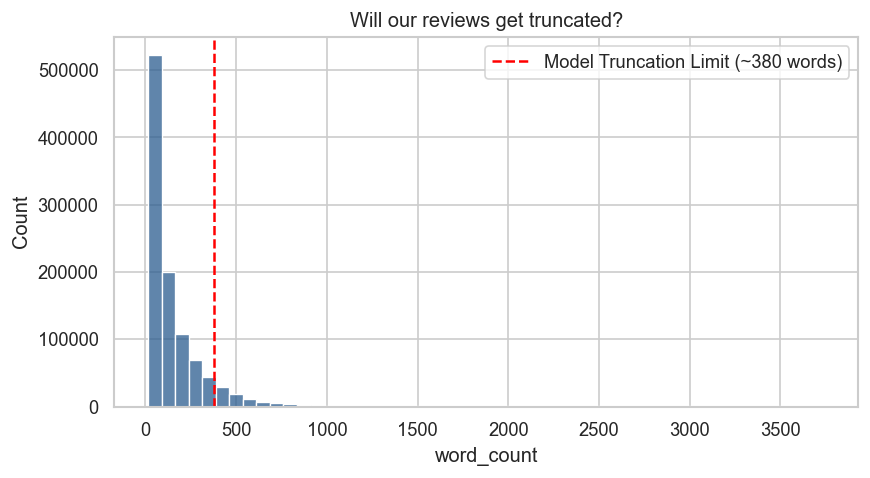

Reviews exceeding model limit: 84,769 (8.3%)


In [5]:
words = df.select("word_count").to_series().to_pandas()
plt.figure(figsize=(8, 4))
sns.histplot(words, bins=50, color="#2b5c8f")
plt.axvline(x=380, color="red", linestyle="--", label="Model Truncation Limit (~380 words)")
plt.title("Will our reviews get truncated?")
plt.legend()
plt.show()

# Calculate the exact loss percentage
oversized = df.filter(pl.col("word_count") > 380).height
print(f"Reviews exceeding model limit: {oversized:,} ({oversized / df.height * 100:.1f}%)")

In [6]:
display(df.describe())

statistic,review_id,book_id,rating,review_text,cleaned_text,word_count,title,description
str,str,str,f64,str,str,f64,str,str
"""count""","""1025532""","""1025532""",1.025532e6,"""1025532""","""1025532""",1.025532e6,"""1025532""","""1025532"""
"""null_count""","""0""","""0""",0.0,"""0""","""0""",0.0,"""0""","""0"""
"""mean""",null,null,3.720723,null,null,146.890534,null,null
"""std""",null,null,1.158124,null,null,167.395371,null,null
"""min""","""0000054dd36436c8c23268c76cccfc…","""10000063""",0.0,"""! This book is compulsively …","""! ! ! ! ! Is Lucas Davenport a…",15.0,"""""...officer down, code three.""""",""""""
"""25%""",null,null,3.0,null,null,41.0,null,null
"""50%""",null,null,4.0,null,null,87.0,null,null
"""75%""",null,null,5.0,null,null,191.0,null,null
"""max""","""fffff70186747eddceb0ae52fe81c1…","""9999847""",5.0,"""~~~~~~~~~~Amanda's Review~~~~~…","""~~~~~~~~~~Amanda's Review~~~~~…",3743.0,"""스노우맨""","""Vi kien truc su tai hoa nam n…"


In [8]:
# Extract the rating column, count the occurrences, and sort them 1 to 5
rating_distribution = df.get_column("rating").value_counts().sort("rating")

display(rating_distribution)

rating,count
i8,u32
0,22952
1,27425
2,80022
3,236809
4,373796
5,284528


In [9]:
# Finds the exact cutoff points for review lengths
percentiles = df.select([
    pl.col("word_count").quantile(0.25).alias("25th Percentile"),
    pl.col("word_count").median().alias("Median (50th)"),
    pl.col("word_count").quantile(0.75).alias("75th Percentile"),
    pl.col("word_count").quantile(0.99).alias("99th Percentile"),
    pl.col("word_count").max().alias("Max")
])

display(percentiles)

25th Percentile,Median (50th),75th Percentile,99th Percentile,Max
f64,f64,f64,f64,u32
41.0,87.0,191.0,773.0,3743


In [10]:
# Calculate total missing and percentage missing
missing_report = (
    df.null_count()
    # Melt turns the wide 1-row table into a vertical column-by-column list
    .unpivot(variable_name="column_name", value_name="null_count")
    .with_columns(
        (pl.col("null_count") / df.height * 100).round(2).alias("percent_missing")
    )
    .sort("null_count", descending=True)
)

display(missing_report)

column_name,null_count,percent_missing
str,u32,f64
"""review_id""",0,0.0
"""book_id""",0,0.0
"""rating""",0,0.0
"""review_text""",0,0.0
"""cleaned_text""",0,0.0
"""word_count""",0,0.0
"""title""",0,0.0
"""description""",0,0.0


In [12]:
controversial_books = (
    df.group_by("title")
    .agg([
        pl.len().alias("review_count"),
        pl.col("rating").mean().round(2).alias("avg_rating"),
        pl.col("rating").std().round(2).alias("rating_variance")
    ])
    .filter(pl.col("review_count") >= 15) # Only look at books with enough data
    .sort("rating_variance", descending=True)
)

print("Most Polarizing Books:")
display(controversial_books.head())

Most Polarizing Books:


title,review_count,avg_rating,rating_variance
str,u32,f64,f64
"""La Reine dans le palais des co…",31,2.0,2.19
"""Desecrating Solomon (Desecrati…",18,3.44,2.15
"""Antidote (Don't..., #2)""",24,3.71,1.99
"""The Black Lizard Big Book of B…",15,3.33,1.95
"""City of God""",16,3.06,1.95


In [13]:
# Calculate the cumulative sum of reviews to find the Pareto distribution
long_tail = (
    df.group_by("title")
    .len()
    .sort("len", descending=True)
    .with_columns([
        (pl.col("len").cum_sum() / df.height * 100).round(2).alias("cumulative_percent_of_all_reviews"),
        ((pl.arange(1, pl.len() + 1) / pl.len()) * 100).round(2).alias("percent_of_total_books")
    ])
)

print("Cumulative Distribution of Reviews:")
display(long_tail.head(10))

Cumulative Distribution of Reviews:


title,len,cumulative_percent_of_all_reviews,percent_of_total_books
str,u32,f64,f64
"""The Girl on the Train""",717,0.07,0.0
"""Gone Girl""",686,0.14,0.0
"""The Girl with the Dragon Tatto…",675,0.2,0.0
"""It""",623,0.26,0.0
"""Rebecca""",577,0.32,0.0
"""And Then There Were None""",560,0.37,0.0
"""Inferno (Robert Langdon, #4)""",551,0.43,0.01
"""The Da Vinci Code (Robert Lang…",474,0.47,0.01
"""Dark Places""",474,0.52,0.01


In [14]:
# Calculate a rough lexical diversity score (unique words / total words)
lexical_richness = (
    df.with_columns([
        # Split text by spaces, get unique list length, divide by total word count
        (pl.col("cleaned_text").str.split(" ").list.unique().list.len() / pl.col("word_count")).alias("lexical_diversity")
    ])
    .group_by("title")
    .agg([
        pl.col("lexical_diversity").mean().round(3).alias("avg_diversity_score"),
        pl.col("word_count").mean().round(0).alias("avg_word_count")
    ])
    .sort("avg_diversity_score", descending=True)
)

print("Books with the highest vocabulary diversity:")
display(lexical_richness.head())

Books with the highest vocabulary diversity:


title,avg_diversity_score,avg_word_count
str,f64,f64
"""Berlin Noir: Penguin eBook (Be…",1.0,33.0
"""Den onda viljan""",1.0,23.0
"""Pep Rally (Horror High, #7)""",1.0,15.0
"""Lucky Thirteen (Chloe Boston M…",1.0,16.0
"""O Inimigo Secreto (Tommy and T…",1.0,20.0


In [15]:
# Check if any single user is dominating the reviews for specific books
user_dominance = (
    df.group_by(["book_id", "title", "review_id"]) # Assuming review_id maps to unique users/reviews
    .len()
    .sort("len", descending=True)
    .filter(pl.col("len") > 1)
)

print(f"Duplicate reviews detected: {user_dominance.height}")
if user_dominance.height > 0:
    display(user_dominance.head())

Duplicate reviews detected: 0


/var/folders/y_/5j08sflx0r5czbk672bqhhgc0000gp/T/ipykernel_14861/1026927730.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_words, x="count", y="word", palette="mako")


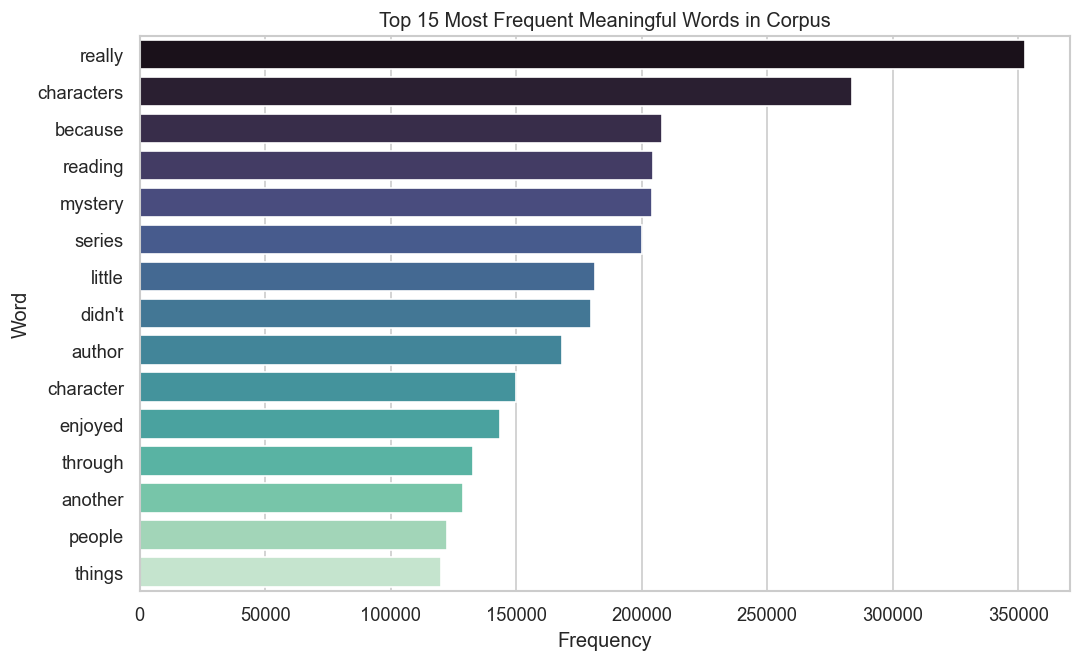

In [7]:
# Split text, explode into rows, filter out tiny words (basic stopword removal), and count
top_words = (
    df.select(pl.col("cleaned_text").str.to_lowercase().str.split(" ").alias("word"))
    .explode("word")
    .filter(pl.col("word").str.len_chars() > 5) # Keep words longer than 5 letters
    .get_column("word")
    .value_counts()
    .sort("count", descending=True)
    .head(15)
    .to_pandas()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_words, x="count", y="word", palette="mako")
plt.title("Top 15 Most Frequent Meaningful Words in Corpus")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

/var/folders/y_/5j08sflx0r5czbk672bqhhgc0000gp/T/ipykernel_14861/774575401.py:3: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  pl.col("word_count")
/var/folders/y_/5j08sflx0r5czbk672bqhhgc0000gp/T/ipykernel_14861/774575401.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=binned_df, x="review_length_category", y="rating", palette="flare")


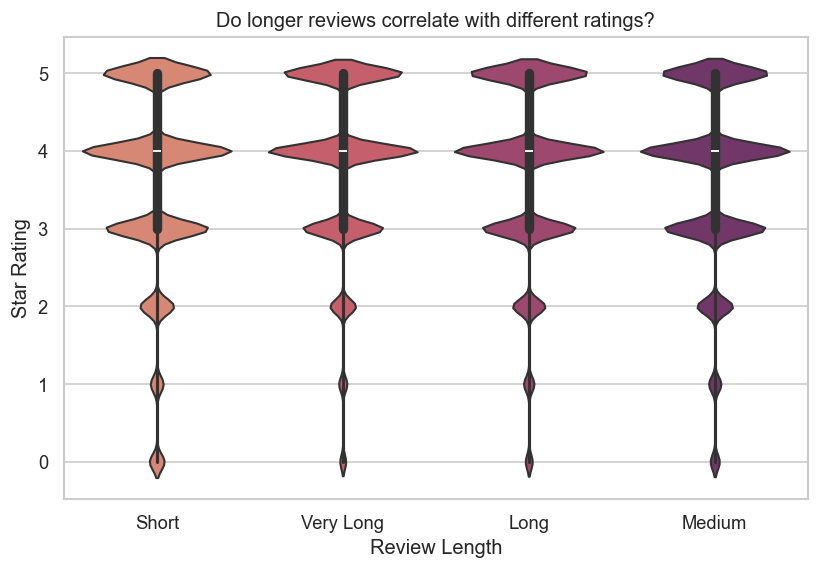

In [8]:
# Bin word counts into 4 distinct categories (Quartiles)
binned_df = df.with_columns(
    pl.col("word_count")
    .qcut(4, labels=["Short", "Medium", "Long", "Very Long"])
    .alias("review_length_category")
).select(["review_length_category", "rating"]).to_pandas()

plt.figure(figsize=(8, 5))
# A violin plot shows both the median (like a boxplot) and the distribution density
sns.violinplot(data=binned_df, x="review_length_category", y="rating", palette="flare")
plt.title("Do longer reviews correlate with different ratings?")
plt.xlabel("Review Length")
plt.ylabel("Star Rating")
plt.show()